# Paper results from the released explanations

Recreates the CoSy tables and figures of the paper from the files in `assets/` 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import wilcoxon

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
plt.rcParams["figure.dpi"] = 110

ASSETS = Path("..") / "assets"
assert (ASSETS / "explanations").is_dir(), "run this notebook from the notebooks/ directory"

DATASET_OF = {
    "resnet18": "imagenet", "resnet50": "imagenet", "vit_b_16": "imagenet",
    "dinov3-vitb16": "imagenet", "resnet18_places": "places365", "resnet50_places": "places365",
}
HEADLINE_LAYER = {
    "resnet18": "avgpool", "resnet50": "avgpool", "resnet18_places": "avgpool",
    "resnet50_places": "avgpool", "vit_b_16": "ln", "dinov3-vitb16": "norm",
}
TABLE_ROWS = [  # (model, label), in the paper's row order
    ("resnet18", "ResNet18 / ImageNet"),
    ("resnet18_places", "ResNet18 / Places365"),
    ("resnet50", "ResNet50 / ImageNet"),
    ("resnet50_places", "ResNet50 / Places365"),
    ("vit_b_16", "ViT-B/16 / ImageNet"),
    ("dinov3-vitb16", "DINOv3 / LVD-1689M"),
]
METHODS = ["LINE", "LINE_flux", "CLIP-Dissect", "INVERT", "DnD"]
BASELINES = ["CLIP-Dissect", "INVERT", "DnD"]
METRICS = ("AUC", "MAD", "Corr")

C_BLUE, C_GREEN, C_RED, C_ORANGE = "#0047AB", "#2E8B57", "#B22222", "#D35400"
METHOD_COLORS = {"LINE": C_BLUE, "CLIP-Dissect": C_GREEN, "INVERT": C_RED, "DnD": C_ORANGE}


def read_dir(kind: str) -> pd.DataFrame:
    frames = []
    for path in sorted((ASSETS / kind).glob("*/*.csv")):
        model = path.stem.rsplit("-", 1)[0]
        frames.append(pd.read_csv(path).assign(method=path.parent.name, model=model))
    df = pd.concat(frames, ignore_index=True)
    df["dataset"] = df["model"].map(DATASET_OF)
    return df


def sel(method: str, model: str, layer: str | None = None) -> pd.DataFrame:
    """One method's explanations of one layer (the model's headline layer by default)."""
    layer = layer or HEADLINE_LAYER[model]
    return data[(data["method"] == method) & (data["model"] == model) & (data["layer"] == layer)]


def fmt(values: pd.Series, metric: str) -> str:
    """'mean ± std' as in the paper's tables, or '--' when the cell has no scores."""
    values = values.dropna()
    if values.empty:
        return "--"
    if metric == "Corr":  # the paper reports Corr x10^-1
        values = 10 * values
    return f"{values.mean():.2f} ± {values.std():.2f}"


data = read_dir("explanations")
histories = read_dir("histories")
pd.DataFrame({
    "layers": data.drop_duplicates(["method", "model", "layer"]).groupby("method").size(),
    "neurons": data.groupby("method").size(),
    "with Corr": data.groupby("method")["Corr"].count(),
    "history rows": histories.groupby("method").size(),
}).reindex(METHODS).fillna(0).astype(int)

,layers,neurons,with Corr,history rows
method,,,,
LINE,26,2528,600,53088
LINE_flux,6,600,600,12600
CLIP-Dissect,26,2528,600,0
INVERT,26,2528,600,0
DnD,10,1000,600,0


## AUC / MAD per (model, layer): mean (± std)

In [2]:
averages = (
    data.groupby(["dataset", "model", "layer", "method"])[["AUC", "MAD"]]
    .agg(["mean", "std"])
)
averages.columns = ["AUC_mean", "AUC_std", "MAD_mean", "MAD_std"]
averages = averages.reset_index()

for metric in ("AUC", "MAD"):
    for model in DATASET_OF:
        sub = averages[averages["model"] == model]
        cells = (sub[f"{metric}_mean"].map("{:.4f}".format)
                 + " (±" + sub[f"{metric}_std"].map("{:.4f}".format) + ")")
        table = sub.assign(cell=cells).pivot(index="method", columns="layer", values="cell")
        print(f"{metric} — {DATASET_OF[model]} / {model}")
        display(table.reindex([m for m in METHODS if m in table.index]).fillna(""))

AUC — imagenet / resnet18


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
LINE,0.9712 (±0.0431),0.8420 (±0.1479),0.9034 (±0.1046),0.9164 (±0.1084),0.9737 (±0.0400)
LINE_flux,0.9501 (±0.0956),,,,
CLIP-Dissect,0.8973 (±0.1375),0.6711 (±0.2558),0.6893 (±0.2402),0.7617 (±0.2374),0.8973 (±0.1375)
INVERT,0.8519 (±0.1410),0.6676 (±0.2037),0.7418 (±0.1976),0.7814 (±0.1691),0.8519 (±0.1410)
DnD,0.7725 (±0.2147),,,,


AUC — imagenet / resnet50


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
LINE,0.9678 (±0.0703),0.8441 (±0.1673),0.8883 (±0.1415),0.9135 (±0.1023),0.9678 (±0.0703)
LINE_flux,0.9512 (±0.1009),,,,
CLIP-Dissect,0.8750 (±0.1765),0.6970 (±0.2295),0.6549 (±0.2580),0.7751 (±0.1954),0.8750 (±0.1765)
INVERT,0.8814 (±0.1542),0.6914 (±0.2167),0.7169 (±0.2089),0.7567 (±0.1838),0.8814 (±0.1542)
DnD,0.8508 (±0.1791),0.6289 (±0.2672),0.6501 (±0.2571),0.7068 (±0.2281),0.8661 (±0.1571)


AUC — imagenet / vit_b_16


layer,encoder_layer_10,encoder_layer_6,encoder_layer_8,ln,ln_1
method,,,,,
LINE,0.9710 (±0.0403),0.8649 (±0.1221),0.8761 (±0.1193),0.9426 (±0.0706),0.9632 (±0.0467)
LINE_flux,,,,0.9182 (±0.1048),
CLIP-Dissect,0.7514 (±0.2093),0.7250 (±0.2002),0.7116 (±0.1957),0.7390 (±0.2007),0.7428 (±0.1799)
INVERT,0.8327 (±0.1320),0.7100 (±0.1827),0.7292 (±0.1406),0.7949 (±0.1755),0.8237 (±0.1428)
DnD,,,,0.6417 (±0.1975),


... (14 outputs left out)

MAD — places365 / resnet18_places


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
LINE,3.7734 (±2.3093),2.2938 (±2.0991),2.5576 (±1.9806),3.6192 (±2.5848),3.7734 (±2.3093)
LINE_flux,3.5068 (±2.4222),,,,
CLIP-Dissect,3.6267 (±2.7838),1.4552 (±2.3653),1.6830 (±2.3531),2.3653 (±2.9872),3.6267 (±2.7838)
INVERT,1.8498 (±1.6993),0.5558 (±0.9443),1.1180 (±1.4943),1.1972 (±1.5886),1.8498 (±1.6993)
DnD,3.1650 (±2.9220),,,,


MAD — places365 / resnet50_places


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
LINE,4.2716 (±2.8069),2.6347 (±2.6548),2.8912 (±3.0400),3.0546 (±2.1281),4.3734 (±2.7576)
LINE_flux,3.8385 (±2.6096),,,,
CLIP-Dissect,3.6936 (±2.9018),1.7839 (±2.0732),1.9967 (±2.3332),2.2266 (±2.6109),3.6936 (±2.9018)
INVERT,2.0409 (±1.6962),0.7297 (±1.0791),1.1163 (±1.2296),1.1572 (±1.2597),2.0409 (±1.6962)
DnD,2.7449 (±2.5596),,,,


## Main comparison table

CoSy AUC and MAD, and Corr: the Pearson correlation between neuron activations and the SigLIP
similarity of each image to the neuron's explanation, reported ×10⁻¹ as in the paper. Every
std is the sample std.

**Note:** four Corr cells of the NeurIPS 2026 camera-ready Table 1 differ from the released
scores (camera-ready → below):

| Row | Method | Camera-ready | Released |
| --- | --- | --- | --- |
| ResNet50 / Places365 | LINE | 0.36 ± 0.56 | 0.36 ± 0.57 |
| Overall | DnD | 0.41 ± 0.49 | 0.41 ± 0.50 |
| Overall | INVERT | 0.24 ± 0.38 | 0.30 ± 0.38 |
| ViT-B/16 / ImageNet | DnD | 0.08 ± 0.15 | 0.07 ± 0.15 | 

No best / second-best marking changes.

In [3]:
def comparison_table(columns: dict[str, str]) -> pd.DataFrame:
    """columns: displayed name -> method."""
    labels = [label for _, label in TABLE_ROWS] + ["Overall"]
    table = {}
    for column, method in columns.items():
        pooled = pd.concat([sel(method, model) for model, _ in TABLE_ROWS])
        table[column] = [
            fmt((pooled if model is None else sel(method, model))[metric], metric)
            for model, _ in [*TABLE_ROWS, (None, "Overall")]
            for metric in METRICS
        ]
    return pd.DataFrame(table, index=pd.MultiIndex.from_product([labels, METRICS]))


comparison_table({m: m for m in ["LINE", "CLIP-Dissect", "INVERT", "DnD"]})

LINE CLIP-Dissect       INVERT          DnD
ResNet18 / ImageNet  AUC   0.97 ± 0.04  0.90 ± 0.14  0.85 ± 0.14  0.77 ± 0.21
                     MAD   4.76 ± 1.91  3.42 ± 2.17  2.16 ± 1.61  1.97 ± 1.99
                     Corr  0.57 ± 0.49  0.41 ± 0.39  0.47 ± 0.45  0.44 ± 0.46
ResNet18 / Places365 AUC   0.93 ± 0.10  0.89 ± 0.15  0.80 ± 0.18  0.85 ± 0.19
                     MAD   3.77 ± 2.31  3.63 ± 2.78  1.85 ± 1.70  3.16 ± 2.92
                     Corr  0.51 ± 0.54  0.29 ± 0.43  0.20 ± 0.33  0.64 ± 0.58
ResNet50 / ImageNet  AUC   0.97 ± 0.07  0.87 ± 0.18  0.88 ± 0.15  0.85 ± 0.18
                     MAD   5.28 ± 2.10  3.56 ± 2.52  2.81 ± 1.95  3.40 ± 3.02
                     Corr  0.81 ± 0.57  0.33 ± 0.46  0.48 ± 0.51  0.66 ± 0.47
ResNet50 / Places365 AUC   0.94 ± 0.08  0.89 ± 0.15  0.84 ± 0.14  0.84 ± 0.18
                     MAD   4.27 ± 2.81  3.69 ± 2.90  2.04 ± 1.70  2.74 ± 2.56
                     Corr  0.36 ± 0.57  0.24 ± 0.48  0.16 ± 0.30  0.57 ± 0.54
ViT-B/16 / ImageNet  AUC   0.94 ± 0.07  0.74 ± 0.20  0.79 ± 0.18  0.64 ± 0.20
                     MAD   2.12 ± 0.54  1.00 ± 0.89  1.05 ± 0.70  0.60 ± 0.84
                     Corr  0.26 ± 0.21  0.07 ± 0.15  0.23 ± 0.21  0.07 ± 0.15
DINOv3 / LVD-1689M   AUC   0.94 ± 0.08  0.76 ± 0.22  0.76 ± 0.18  0.62 ± 0.23
                     MAD   2.05 ± 0.68  1.12 ± 1.06  0.95 ± 0.73  0.47 ± 0.92
                     Corr  0.32 ± 0.23  0.09 ± 0.20  0.24 ± 0.24  0.11 ± 0.21
Overall              AUC   0.95 ± 0.08  0.84 ± 0.19  0.82 ± 0.17  0.76 ± 0.22
                     MAD   3.71 ± 2.27  2.74 ± 2.50  1.81 ± 1.61  2.06 ± 2.50
                     Corr  0.47 ± 0.50  0.24 ± 0.39  0.30 ± 0.38  0.41 ± 0.50

## Extended comparison table: LINE vs. LINE (FLUX) vs. best baseline

*Baseline* is, per row and metric, the baseline (CLIP-Dissect, INVERT or DnD) with the
highest mean; in the *Overall* row it is the baseline with the highest overall mean.

In [4]:
labels = [label for _, label in TABLE_ROWS] + ["Overall"]
extended = {"LINE": {}, "LINE (FLUX)": {}, "Baseline": {}}


def scores(method: str, model: str | None, metric: str) -> pd.Series:
    """One method's scores in one table row; model=None pools all rows (the Overall row)."""
    if model is None:
        return pd.concat([sel(method, m) for m, _ in TABLE_ROWS])[metric]
    return sel(method, model)[metric]


for metric in METRICS:
    for model, label in [*TABLE_ROWS, (None, "Overall")]:
        best = max(BASELINES, key=lambda m: scores(m, model, metric).mean())
        for column, method in (("LINE", "LINE"), ("LINE (FLUX)", "LINE_flux"), ("Baseline", best)):
            extended[column][(label, metric)] = fmt(scores(method, model, metric), metric)

index = pd.MultiIndex.from_product([labels, METRICS])
pd.DataFrame({column: [cells[i] for i in index] for column, cells in extended.items()}, index=index)

LINE  LINE (FLUX)     Baseline
ResNet18 / ImageNet  AUC   0.97 ± 0.04  0.95 ± 0.10  0.90 ± 0.14
                     MAD   4.76 ± 1.91  4.45 ± 2.06  3.42 ± 2.17
                     Corr  0.57 ± 0.49  0.66 ± 0.46  0.47 ± 0.45
ResNet18 / Places365 AUC   0.93 ± 0.10  0.90 ± 0.16  0.89 ± 0.15
                     MAD   3.77 ± 2.31  3.51 ± 2.42  3.63 ± 2.78
                     Corr  0.51 ± 0.54  0.53 ± 0.47  0.64 ± 0.58
ResNet50 / ImageNet  AUC   0.97 ± 0.07  0.95 ± 0.10  0.88 ± 0.15
                     MAD   5.28 ± 2.10  4.92 ± 2.16  3.56 ± 2.52
                     Corr  0.81 ± 0.57  0.65 ± 0.46  0.66 ± 0.47
ResNet50 / Places365 AUC   0.94 ± 0.08  0.93 ± 0.09  0.89 ± 0.15
                     MAD   4.27 ± 2.81  3.84 ± 2.61  3.69 ± 2.90
                     Corr  0.36 ± 0.57  0.35 ± 0.45  0.57 ± 0.54
ViT-B/16 / ImageNet  AUC   0.94 ± 0.07  0.92 ± 0.10  0.79 ± 0.18
                     MAD   2.12 ± 0.54  1.90 ± 0.65  1.05 ± 0.70
                     Corr  0.26 ± 0.21  0.26 ± 0.21  0.23 ± 0.21
DINOv3 / LVD-1689M   AUC   0.94 ± 0.08  0.91 ± 0.12  0.76 ± 0.18
                     MAD   2.05 ± 0.68  1.86 ± 0.78  1.12 ± 1.06
                     Corr  0.32 ± 0.23  0.29 ± 0.21  0.24 ± 0.24
Overall              AUC   0.95 ± 0.08  0.93 ± 0.12  0.84 ± 0.19
                     MAD   3.71 ± 2.27  3.41 ± 2.26  2.74 ± 2.50
                     Corr  0.47 ± 0.50  0.46 ± 0.43  0.41 ± 0.50

## Statistical significance: LINE > baseline

One-sided Wilcoxon signed-rank test, paired by neuron. Cells are `p(AUC) | p(MAD)`;
`*` marks a cell where either p-value is above 0.05.

In [5]:
tests = []
for (model, layer), group in data.groupby(["model", "layer"]):
    line = group[group["method"] == "LINE"].set_index("unit")
    for other in BASELINES:
        merged = line.join(group[group["method"] == other].set_index("unit"), rsuffix="_o", how="inner")
        if merged.empty:
            continue
        tests.append({
            "model": model, "layer": layer, "method": other,
            "p_AUC": wilcoxon(merged["AUC"], merged["AUC_o"], alternative="greater").pvalue,
            "p_MAD": wilcoxon(merged["MAD"], merged["MAD_o"], alternative="greater").pvalue,
        })
tests = pd.DataFrame(tests)
tests["cell"] = (
    tests["p_AUC"].map("{:.4f}".format) + " | " + tests["p_MAD"].map("{:.4f}".format)
    + np.where((tests["p_AUC"] > 0.05) | (tests["p_MAD"] > 0.05), " *", "")
)
for model in DATASET_OF:
    print(model)
    display(tests[tests["model"] == model].pivot(index="method", columns="layer", values="cell").fillna(""))

resnet18


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
CLIP-Dissect,0.0000 | 0.0000,0.0000 | 0.0022,0.0000 | 0.0000,0.0000 | 0.0001,0.0000 | 0.0000
DnD,0.0000 | 0.0000,,,,
INVERT,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000


resnet50


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
CLIP-Dissect,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000
DnD,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000
INVERT,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000


vit_b_16


layer,encoder_layer_10,encoder_layer_6,encoder_layer_8,ln,ln_1
method,,,,,
CLIP-Dissect,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000
DnD,,,,0.0000 | 0.0000,
INVERT,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000


... (2 outputs left out)

resnet18_places


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
CLIP-Dissect,0.0125 | 0.1472 *,0.0000 | 0.0001,0.0000 | 0.0000,0.0000 | 0.0000,0.0125 | 0.1472 *
DnD,0.0000 | 0.0005,,,,
INVERT,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000


resnet50_places


layer,avgpool,layer1,layer2,layer3,layer4
method,,,,,
CLIP-Dissect,0.0020 | 0.0083,0.0000 | 0.0002,0.0000 | 0.0000,0.0000 | 0.0002,0.0005 | 0.0028
DnD,0.0000 | 0.0000,,,,
INVERT,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000,0.0000 | 0.0000


## T2I generator: LINE (SDXL) vs. LINE (FLUX)

The same neurons explained by LINE with SDXL (the default) and with FLUX.1-dev, at each
model's headline layer. p-values are from a two-sided Wilcoxon signed-rank test, paired
by neuron.

In [6]:
def t2i_row(merged: pd.DataFrame, label: str) -> dict:
    row = {"Model": label, "n": len(merged)}
    for metric in ("AUC", "MAD"):
        row[f"{metric} SDXL"] = fmt(merged[f"{metric}_sdxl"], metric)
        row[f"{metric} FLUX"] = fmt(merged[f"{metric}_flux"], metric)
        row[f"{metric} p"] = wilcoxon(merged[f"{metric}_sdxl"], merged[f"{metric}_flux"]).pvalue
    row["Same concept (%)"] = 100 * (merged["description_sdxl"] == merged["description_flux"]).mean()
    return row


merged_all = []
t2i = []
for model, label in TABLE_ROWS:
    merged = sel("LINE", model).merge(sel("LINE_flux", model), on="unit", suffixes=("_sdxl", "_flux"))
    merged_all.append(merged)
    t2i.append(t2i_row(merged, label))
t2i.append(t2i_row(pd.concat(merged_all), "Overall"))
pd.DataFrame(t2i).set_index("Model").round({"AUC p": 4, "MAD p": 4, "Same concept (%)": 0})

,n,AUC SDXL,AUC FLUX,AUC p,MAD SDXL,MAD FLUX,MAD p,Same concept (%)
Model,,,,,,,,
ResNet18 / ImageNet,100,0.97 ± 0.04,0.95 ± 0.10,0.0976,4.76 ± 1.91,4.45 ± 2.06,0.0502,40.0
ResNet18 / Places365,100,0.93 ± 0.10,0.90 ± 0.16,0.0809,3.77 ± 2.31,3.51 ± 2.42,0.0716,28.0
ResNet50 / ImageNet,100,0.97 ± 0.07,0.95 ± 0.10,0.0033,5.28 ± 2.10,4.92 ± 2.16,0.0201,41.0
ResNet50 / Places365,100,0.94 ± 0.08,0.93 ± 0.09,0.0766,4.27 ± 2.81,3.84 ± 2.61,0.0072,24.0
ViT-B/16 / ImageNet,100,0.94 ± 0.07,0.92 ± 0.10,0.0502,2.12 ± 0.54,1.90 ± 0.65,0.0010,37.0
DINOv3 / LVD-1689M,100,0.94 ± 0.08,0.91 ± 0.12,0.0013,2.05 ± 0.68,1.86 ± 0.78,0.0006,38.0
Overall,600,0.95 ± 0.08,0.93 ± 0.12,0.0000,3.71 ± 2.27,3.41 ± 2.26,0.0000,35.0


## AUC by layer

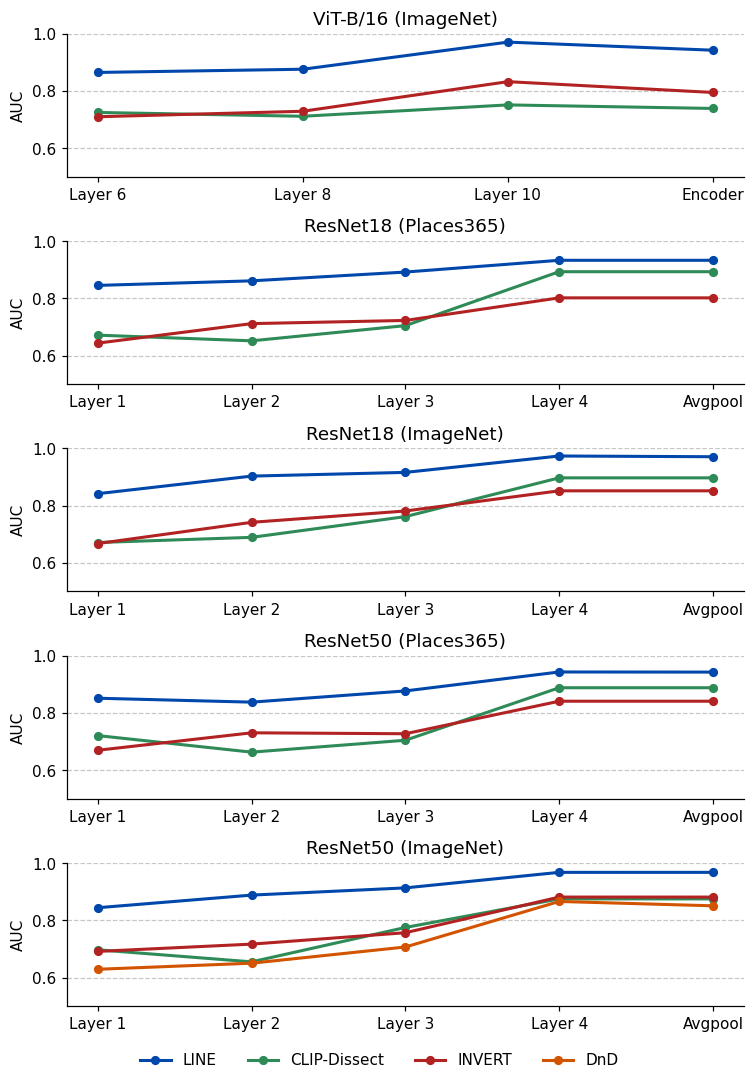

In [7]:
RESNET_LAYERS = (["layer1", "layer2", "layer3", "layer4", "avgpool"],
                 ["Layer 1", "Layer 2", "Layer 3", "Layer 4", "Avgpool"])
VIT_LAYERS = (["encoder_layer_6", "encoder_layer_8", "encoder_layer_10", "ln"],
              ["Layer 6", "Layer 8", "Layer 10", "Encoder"])
PANELS = [
    ("vit_b_16", VIT_LAYERS, "ViT-B/16 (ImageNet)"),
    ("resnet18_places", RESNET_LAYERS, "ResNet18 (Places365)"),
    ("resnet18", RESNET_LAYERS, "ResNet18 (ImageNet)"),
    ("resnet50_places", RESNET_LAYERS, "ResNet50 (Places365)"),
    ("resnet50", RESNET_LAYERS, "ResNet50 (ImageNet)"),
]

fig, axes = plt.subplots(5, 1, figsize=(7, 10))
for ax, (model, (layers, layer_labels), title) in zip(axes, PANELS, strict=True):
    for method in ["LINE", "CLIP-Dissect", "INVERT", "DnD"]:
        # DnD covers every layer only for ResNet50 / ImageNet; elsewhere it is one point.
        if method == "DnD" and model != "resnet50":
            continue
        means = data[(data["method"] == method) & (data["model"] == model)].groupby("layer")["AUC"].mean()
        ax.plot(range(len(layers)), [means.get(layer, np.nan) for layer in layers], label=method,
                color=METHOD_COLORS[method], linewidth=2.0, marker="o", markersize=5.0)
    ax.set_xticks(range(len(layers)), layer_labels)
    ax.set_title(title)
    ax.set_ylabel("AUC")
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", alpha=0.7, linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)
handles, legend_labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 0.05), ncol=4, frameon=False)
plt.tight_layout()
plt.subplots_adjust(bottom=0.08, hspace=0.45)
plt.show()

## Where LINE's reported concept comes from

Each reported concept is classified by the earliest step that produced it: the initial
vocabulary pool (`stage == "initial"`), an LLM iteration, or the summary call.

,provenance,n_neurons,initial vocabulary,LLM iteration,LLM summary
model,layer,,,,
resnet50,avgpool,100,79,17,4
resnet50_places,avgpool,100,66,26,8
resnet18,avgpool,100,82,17,1
resnet18_places,avgpool,100,56,38,6
vit_b_16,ln,100,83,16,1
dinov3-vitb16,norm,100,83,15,2


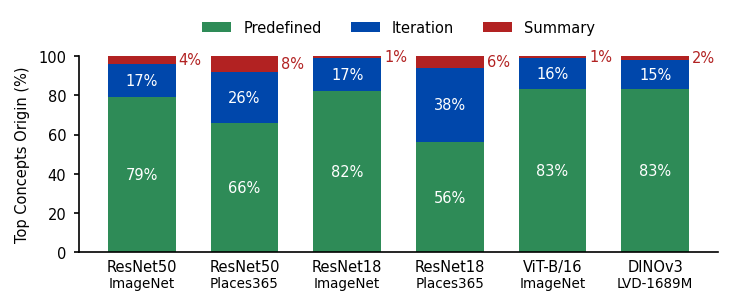

In [8]:
PROV_ORDER = ["initial vocabulary", "LLM iteration", "LLM summary"]
HEADLINE = [("resnet50", "ImageNet"), ("resnet50_places", "Places365"), ("resnet18", "ImageNet"),
            ("resnet18_places", "Places365"), ("vit_b_16", "ImageNet"), ("dinov3-vitb16", "LVD-1689M")]


def provenance(method: str) -> pd.DataFrame:
    hist = histories[histories["method"] == method]
    sources = {
        key: (set(g.loc[g["stage"] == "initial", "concept"]),
              set(g.loc[g["stage"] == "iteration", "concept"]),
              g.loc[g["stage"] == "summary", "concept"].iloc[0])
        for key, g in hist.groupby(["model", "layer", "unit"])
    }
    records = []
    for row in data[data["method"] == method].itertuples():
        initial, loop, summary = sources[(row.model, row.layer, row.unit)]
        origin = ("initial vocabulary" if row.description in initial else
                  "LLM iteration" if row.description in loop else
                  "LLM summary" if row.description == summary else "LLM iteration")
        records.append({"model": row.model, "layer": row.layer, "provenance": origin})
    counts = pd.DataFrame(records).groupby(["model", "layer", "provenance"]).size().unstack(fill_value=0)
    counts = counts.reindex(columns=PROV_ORDER, fill_value=0)
    counts.insert(0, "n_neurons", counts.sum(axis=1))
    return counts


prov = provenance("LINE").loc[[(m, HEADLINE_LAYER[m]) for m, _ in HEADLINE]]
display(prov)

fig, ax = plt.subplots(figsize=(5.5, 1.7), dpi=150)
pct = 100 * prov[PROV_ORDER].div(prov["n_neurons"], axis=0)
bottom = np.zeros(len(pct))
for seg, color, label in zip(PROV_ORDER, [C_GREEN, C_BLUE, C_RED], ["Predefined", "Iteration", "Summary"], strict=True):
    ax.bar(range(len(pct)), pct[seg], bottom=bottom, width=0.66, color=color, label=label, zorder=2)
    for xi, (v, b) in enumerate(zip(pct[seg], bottom, strict=True)):
        if v >= 9:
            ax.text(xi, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=7, color="white")
        elif v > 0:
            ax.text(xi + 0.36, b + v / 2, f"{v:.0f}%", ha="left", va="center", fontsize=7, color=color)
    bottom += pct[seg].to_numpy()
names = {"resnet18": "ResNet18", "resnet18_places": "ResNet18", "resnet50": "ResNet50",
         "resnet50_places": "ResNet50", "vit_b_16": "ViT-B/16", "dinov3-vitb16": "DINOv3"}
ax.set_xticks(range(len(pct)), [names[m] for m, _ in HEADLINE], fontsize=7)
for xi, (_, dataset) in enumerate(HEADLINE):
    ax.text(xi, -0.12, dataset, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=6.5)
ax.set_ylim(0, 100)
ax.set_ylabel("Top Concepts Origin (%)", fontsize=7)
ax.tick_params(labelsize=7, length=2.5)
ax.tick_params(axis="x", length=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=3, frameon=False, fontsize=7)
plt.show()

## LINE scoreboards of the main-figure neurons

The final scoreboard holds every concept with its score. `vocab` marks concepts
from the initial vocabulary pool, `llm` concepts the LLM proposed, and `◆` the summary
concept.

In [9]:
def scoreboard(method: str, model: str, layer: str, unit: int) -> pd.DataFrame:
    hist = histories[(histories["method"] == method) & (histories["model"] == model)
                     & (histories["layer"] == layer) & (histories["unit"] == unit)]
    board = hist.groupby("concept", sort=False)["score"].last()
    initial = set(hist.loc[hist["stage"] == "initial", "concept"])
    summary = hist.loc[hist["stage"] == "summary", "concept"].iloc[0]
    board = board.sort_values(ascending=False, kind="stable").reset_index()
    board["source"] = np.where(board["concept"].isin(initial), "vocab", "llm")
    board["summary"] = board["concept"] == summary
    return board


for model, layer, unit in [("vit_b_16", "ln", 488), ("resnet50_places", "avgpool", 1912), ("resnet18", "avgpool", 460)]:
    board = scoreboard("LINE", model, layer, unit)
    top = board.head(6)
    if not top["summary"].any():
        top = pd.concat([top, board[board["summary"]]])
    print(f"== {model}/{layer} neuron {unit}")
    for r in top.itertuples():
        print(f"   {r.source:5s} {'◆' if r.summary else ' '} {r.score:+.3f}  {r.concept}")
    explanations = " | ".join(
        f"{m}: {row['description'].iloc[0]} (AUC {row['AUC'].iloc[0]:.3f})"
        for m in ["LINE", "CLIP-Dissect", "INVERT"]
        for row in [sel(m, model, layer).query("unit == @unit")]
    )
    print(f"   +{len(board) - len(top)} more in scoreboard | {explanations}\n")

== vit_b_16/ln neuron 488
   llm   ◆ +1.497  image projector
   llm     +1.366  projector device
   vocab   +1.215  projector
   vocab   +1.174  reflex camera
   llm     +1.059  projector camera
   llm     +1.024  camera
   +13 more in scoreboard | LINE: image projector (AUC 0.935) | CLIP-Dissect: grounds (AUC 0.803) | INVERT: personal computer (AUC 0.759)

== resnet50_places/avgpool neuron 1912
   llm     +2.209  frozen landscape
   llm   ◆ +2.148  cold environment
   llm     +1.915  tundra
   llm     +1.887  permafrost
   llm     +1.741  glacier
   vocab   +1.683  volcano
   +15 more in scoreboard | LINE: frozen landscape (AUC 0.991) | CLIP-Dissect: yellowstone (AUC 0.985) | INVERT: bear (AUC 0.898)

== resnet18/avgpool neuron 460
   llm     +6.812  aquatic biome
   llm     +6.494  vibrant ecosystem
   llm     +6.284  marine ecosystem
   vocab   +5.300  coral reef
   llm     +5.132  underwater landscape
   llm     +4.430  reef
   llm   ◆ +3.276  underwater
   +14 more in scoreboard |